In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv('C:\\Users\\Tushar\\OneDrive\\Documents\\Netflix-Data-Analysis\\dataset\\netflix_titles.csv')
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [4]:
df.shape

(8807, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [6]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [7]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [8]:
df_clean = df.copy()

In [9]:
print("Total duplicate rows:", df_clean.duplicated().sum())

Total duplicate rows: 0


In [10]:
df_clean['director'] = df_clean['director'].fillna('Unknown')
df_clean['cast'] = df_clean['cast'].fillna('Unknown')
df_clean['country'] = df_clean['country'].fillna('Unknown')
df_clean['rating'] = df_clean['rating'].fillna('Unknown')

In [11]:
df_clean['date_added'] = pd.to_datetime(df_clean['date_added'].str.strip(), format='%B %d, %Y', errors='coerce')

In [12]:
print(df_clean.isnull().sum())

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64


In [13]:
print(df_clean.info())

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   str           
 1   type          8807 non-null   str           
 2   title         8807 non-null   str           
 3   director      8807 non-null   str           
 4   cast          8807 non-null   str           
 5   country       8807 non-null   str           
 6   date_added    8797 non-null   datetime64[us]
 7   release_year  8807 non-null   int64         
 8   rating        8807 non-null   str           
 9   duration      8804 non-null   str           
 10  listed_in     8807 non-null   str           
 11  description   8807 non-null   str           
dtypes: datetime64[us](1), int64(1), str(10)
memory usage: 3.8 MB
None


In [14]:
content_count = df_clean['type'].value_counts()

print(content_count)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [15]:
content_percentage = df_clean['type'].value_counts(normalize=True) * 100
print(content_percentage)

type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64


In [19]:
year_counts = df_clean['release_year'].value_counts().sort_index()
print(year_counts.tail(15))

release_year
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


In [21]:
highest_year = df_clean['release_year'].value_counts().idxmax()
print("Year with highest content count:", highest_year)

Year with highest content count: 2018


In [24]:
country_counts = (
    df_clean['country']
    .str.split(',')
    .explode()
    .str.strip()
)

top_countries = country_counts.value_counts().head(10)

print(top_countries)

country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


In [26]:
rating_counts = df_clean['rating'].value_counts()
print(rating_counts.head(5))

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64


In [29]:
genre_counts = (
    df_clean['listed_in']
    .str.split(',')
    .explode()
    .str.strip()
)

top_genres = genre_counts.value_counts().head(10)

print(top_genres)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


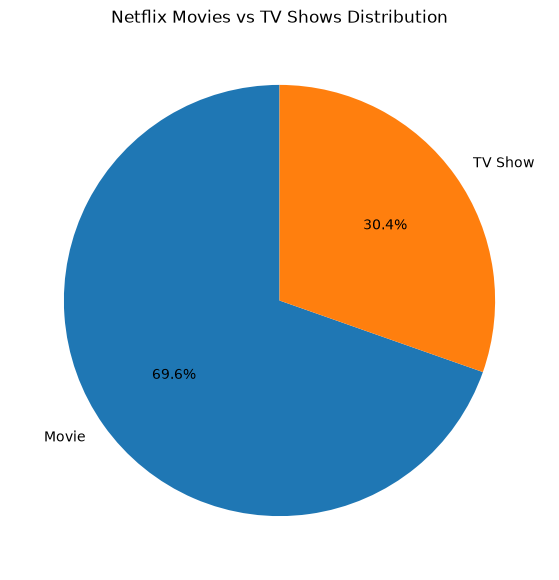

In [49]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_count,
    labels=content_count.index,
    autopct='%1.1f%%',
    startangle=90,
)

plt.title("Netflix Movies vs TV Shows Distribution")
plt.savefig("C:\\Users\\Tushar\\OneDrive\\Documents\\Netflix-Data-Analysis\\visualizations\\content_distribution.png", bbox_inches='tight')
plt.show()

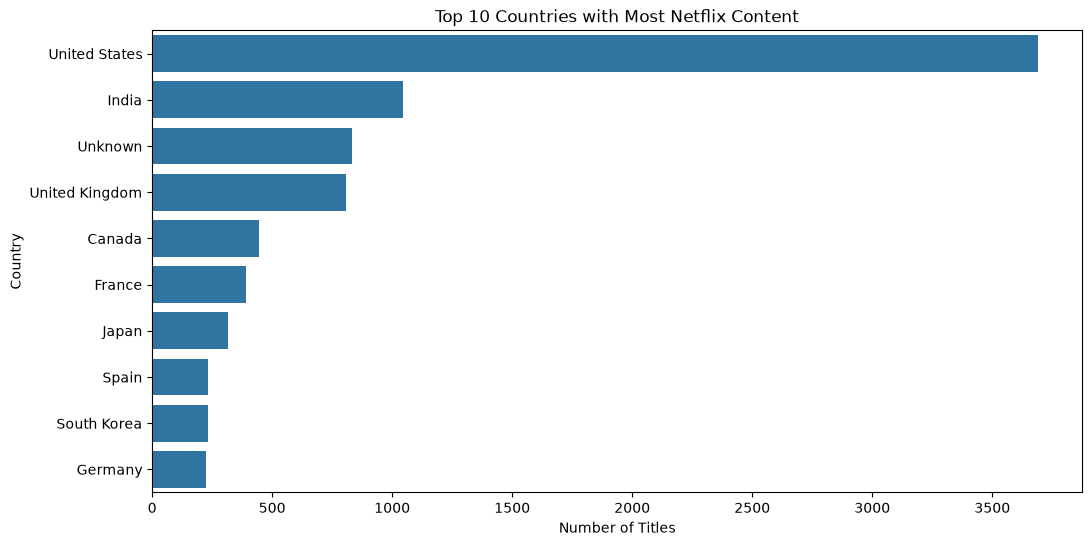

In [48]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
)

plt.title("Top 10 Countries with Most Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.savefig("C:\\Users\\Tushar\\OneDrive\\Documents\\Netflix-Data-Analysis\\visualizations\\top_countries.png", bbox_inches='tight')
plt.show()

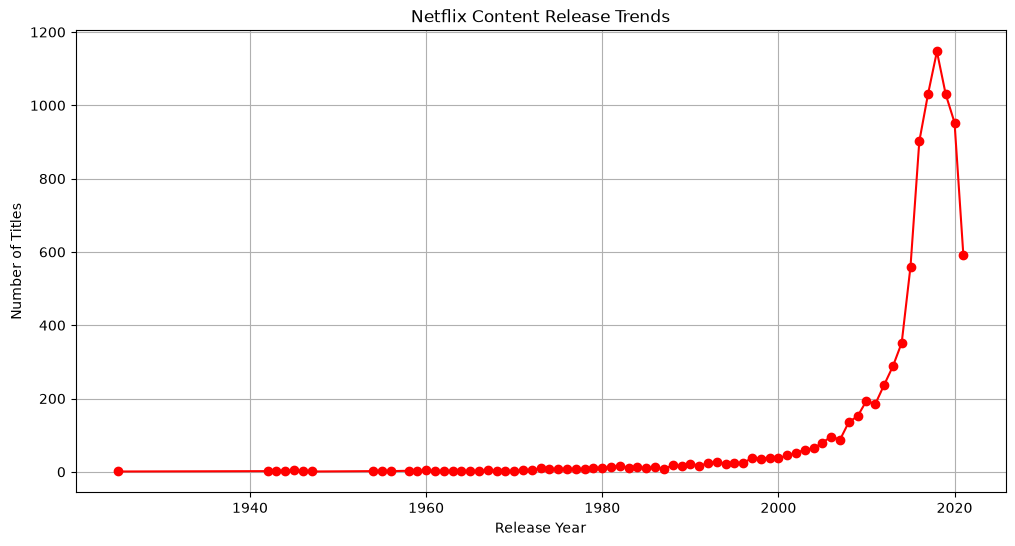

In [ ]:
yearly_content = df_clean['release_year'].value_counts().sort_index()

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_content .index,
    yearly_content.values,
    marker='o',
    color='r'
)

plt.title("Netflix Content Release Trends")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.grid(True)
plt.savefig("C:\\Users\\Tushar\\OneDrive\\Documents\\Netflix-Data-Analysis\\visualizations\\release_trends.png", bbox_inches='tight')
plt.show()

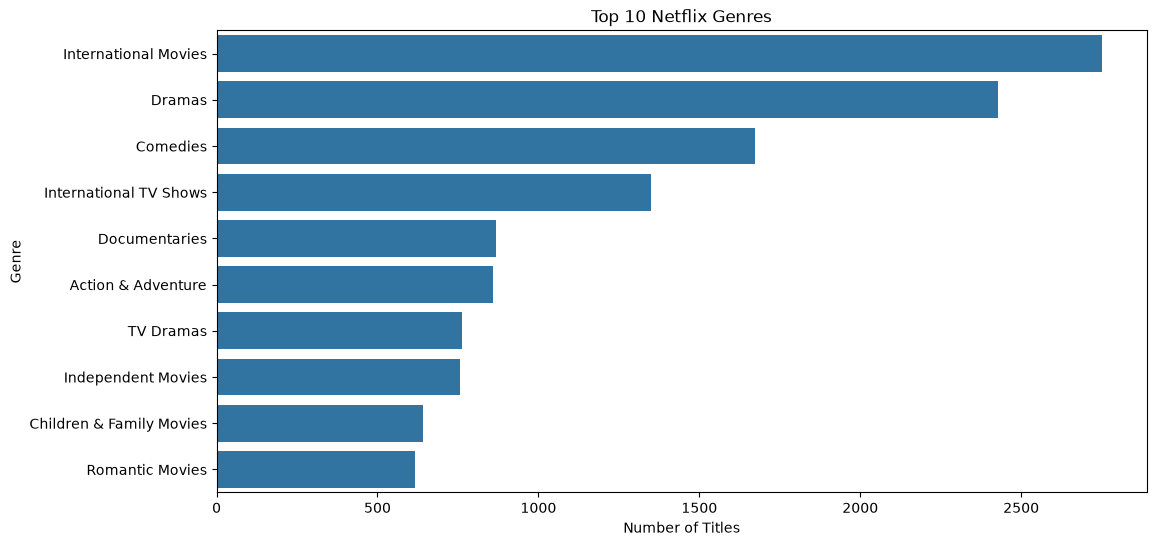

In [47]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.savefig("C:\\Users\\Tushar\\OneDrive\\Documents\\Netflix-Data-Analysis\\visualizations\\top_genres.png", bbox_inches='tight')
plt.show()

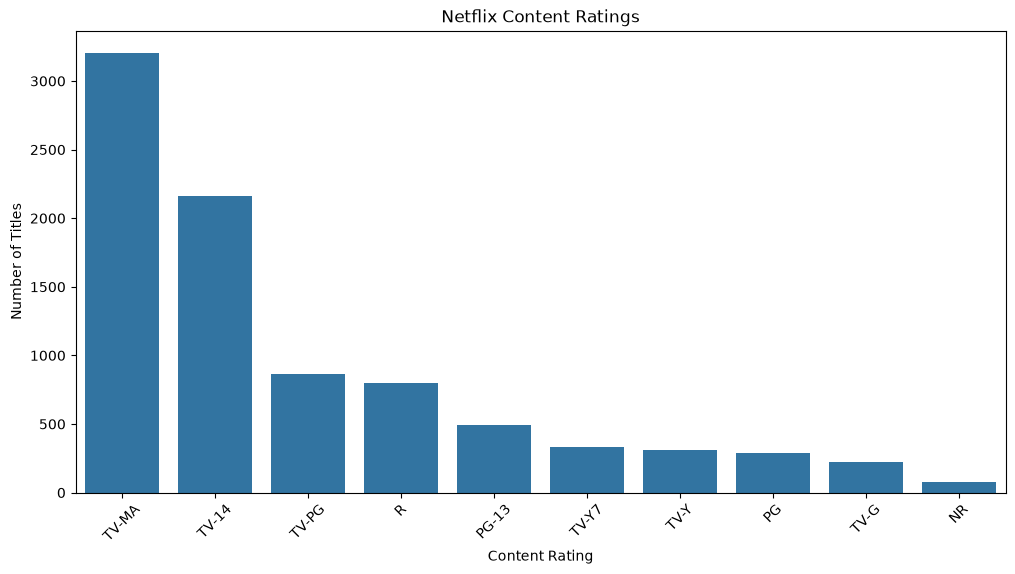

In [45]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    x='rating',
    order=df_clean['rating'].value_counts().index[:10]
)

plt.title("Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.savefig("C:\\Users\\Tushar\\OneDrive\\Documents\\Netflix-Data-Analysis\\visualizations\\netflix_content_ratings.pdf", bbox_inches='tight')
plt.show()

In [50]:
print(df_clean['type'].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [51]:
yearly_content = df_clean['release_year'].value_counts().sort_index()

print(yearly_content.tail(10))

release_year
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


In [53]:
print(top_genres)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [54]:
print(top_countries)

country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


In [55]:
print(rating_counts.head(10))

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


# Netflix Data Analysis - Business Insights

## 1. Content Distribution
Movie      6131
TV Show    2676

## 2. Content Release Trends
2018 In highest TV Show and Movie release 

## 3. Country Analysis
United States release highest TV Show and Movies

## 4. Content Ratings
TV-MA is highest rating

## 5. Genre Analysis
International Movies make mostly 

## 6. Business Recommendations
If international content represents a significant portion of the library, Netflix could investigate regional audience preferences and explore partnerships with local production companies.
